# **Deep Learning - Lab 4 - Raja Rayyan Ameer - 23-CP-25**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(3)
np.set_printoptions(precision=5, suppress=True)

## **Dataset Specification**

X_train: (2, 120) Y_train: (1, 120)
X_test:  (2, 280) Y_test:  (1, 280)
Positive fraction, full dataset: 0.5
Positive fraction, training: 0.45
Positive fraction, test: 0.5214285714285715


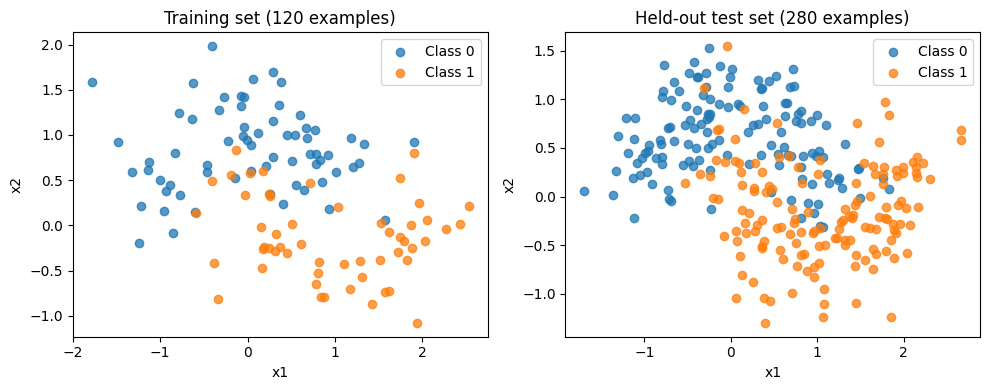

In [2]:
Xr, yr = make_moons(n_samples=400, noise=0.35, random_state=3)
X = Xr.T.astype(float)
Y = yr.reshape(1, -1).astype(float)
X_train, Y_train = X[:, :120], Y[:, :120]
X_test, Y_test = X[:, 120:], Y[:, 120:]

print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_test: ", X_test.shape, "Y_test: ", Y_test.shape)
print("Positive fraction, full dataset:", float(Y.mean()))
print("Positive fraction, training:", float(Y_train.mean()))
print("Positive fraction, test:", float(Y_test.mean()))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, xx, yy, title in [(ax[0], X_train, Y_train, "Training set (120 examples)"),
                         (ax[1], X_test, Y_test, "Held-out test set (280 examples)")]:
    a.scatter(xx[0, yy.ravel()==0], xx[1, yy.ravel()==0], label="Class 0", alpha=.75)
    a.scatter(xx[0, yy.ravel()==1], xx[1, yy.ravel()==1], label="Class 1", alpha=.75)
    a.set_title(title); a.set_xlabel("x1"); a.set_ylabel("x2"); a.legend()
plt.tight_layout()
plt.show()

## **Shared NumPy-only Neural-Network Implementation**

In [3]:
def initialize_parameters(layer_dims, mode="he", seed=None):
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        fan_in, fan_out = layer_dims[l-1], layer_dims[l]
        W = rng.standard_normal((fan_out, fan_in))
        if mode == "zeros":
            W = np.zeros_like(W)
        elif mode == "small":
            W = W * 0.01
        elif mode == "he":
            W = W * np.sqrt(2.0 / fan_in)
        elif mode == "large":
            W = W * 10.0
        else:
            raise ValueError("mode must be zeros, small, he, or large")
        params[f"W{l}"] = W
        params[f"b{l}"] = np.zeros((fan_out, 1))
    return params

def sigmoid(z):
    # Stable sigmoid for large positive/negative inputs
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

def forward_propagation(X, params, keep_prob=1.0, training=False, seed=None):
    L = len(params) // 2
    A = X
    cache = {"A0": X}
    rng = np.random.default_rng(seed)
    for l in range(1, L):
        Z = params[f"W{l}"] @ A + params[f"b{l}"]
        A = np.maximum(0, Z)
        cache[f"Z{l}"] = Z
        if training and keep_prob < 1.0:
            D = (rng.random(A.shape) < keep_prob).astype(float)
            A = A * D / keep_prob
            cache[f"D{l}"] = D
        cache[f"A{l}"] = A
    ZL = params[f"W{L}"] @ A + params[f"b{L}"]
    AL = sigmoid(ZL)
    cache[f"Z{L}"] = ZL
    cache[f"A{L}"] = AL
    return AL, cache

def compute_cost(AL, Y, params=None, lambd=0.0):
    m = Y.shape[1]
    eps = 1e-12
    ce = -np.sum(Y*np.log(AL+eps) + (1-Y)*np.log(1-AL+eps)) / m
    if lambd > 0 and params is not None:
        l2 = sum(np.sum(params[f"W{l}"]**2) for l in range(1, len(params)//2 + 1))
        ce += (lambd / (2*m)) * l2
    return float(ce)

def backward_propagation(AL, Y, params, cache, lambd=0.0, keep_prob=1.0):
    m = Y.shape[1]
    L = len(params) // 2
    grads = {}
    dZ = AL - Y
    for l in reversed(range(1, L+1)):
        A_prev = cache[f"A{l-1}"]
        grads[f"dW{l}"] = (dZ @ A_prev.T) / m + (lambd/m)*params[f"W{l}"]
        grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True) / m
        if l > 1:
            dA = params[f"W{l}"].T @ dZ
            if keep_prob < 1.0:
                dA = dA * cache[f"D{l-1}"] / keep_prob
            Z_prev = cache[f"Z{l-1}"]
            dZ = dA * (Z_prev > 0).astype(float)
    return grads

def update_parameters(params, grads, learning_rate):
    updated = {}
    for key, value in params.items():
        grad_key = "d" + key
        updated[key] = value - learning_rate * grads[grad_key]
    return updated

def predict(X, params):
    # Test-time prediction deliberately has dropout disabled.
    AL, _ = forward_propagation(X, params, keep_prob=1.0, training=False)
    return (AL >= 0.5).astype(float)

def accuracy(X, Y, params):
    return float(np.mean(predict(X, params) == Y) * 100.0)

def weight_norm(params):
    return float(np.sqrt(sum(np.sum(params[f"W{l}"]**2) for l in range(1, len(params)//2 + 1))))

def train_model(Xtr, Ytr, Xte, Yte, layer_dims=(2,20,20,20,1),
                iterations=3000, learning_rate=0.3, init_mode="he",
                lambd=0.0, keep_prob=1.0, seed=10, log_every=None):
    params = initialize_parameters(layer_dims, mode=init_mode, seed=seed)
    history = {"iteration": [], "cost": [], "train_acc": [], "test_acc": []}
    rng = np.random.default_rng(seed + 1000)
    for i in range(1, iterations+1):
        # Use a fresh deterministic seed per iteration for reproducible dropout masks.
        dropout_seed = int(rng.integers(0, 2**31-1))
        AL, cache = forward_propagation(Xtr, params, keep_prob, training=True, seed=dropout_seed)
        cost = compute_cost(AL, Ytr, params, lambd)
        grads = backward_propagation(AL, Ytr, params, cache, lambd, keep_prob)
        params = update_parameters(params, grads, learning_rate)
        if log_every and (i % log_every == 0 or i == 1 or i == iterations):
            history["iteration"].append(i)
            history["cost"].append(cost)
            history["train_acc"].append(accuracy(Xtr, Ytr, params))
            history["test_acc"].append(accuracy(Xte, Yte, params))
    return params, history

def plot_decision_boundary(ax, params, title, Xdata=X, Ydata=Y):
    x_min, x_max = Xdata[0].min()-0.5, Xdata[0].max()+0.5
    y_min, y_max = Xdata[1].min()-0.5, Xdata[1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 220), np.linspace(y_min, y_max, 220))
    grid = np.vstack([xx.ravel(), yy.ravel()])
    probs, _ = forward_propagation(grid, params, training=False)
    zz = (probs.reshape(xx.shape) >= .5).astype(int)
    ax.contourf(xx, yy, zz, alpha=.22, levels=[-.5,.5,1.5])
    ax.scatter(Xdata[0, Ydata.ravel()==0], Xdata[1, Ydata.ravel()==0], s=12, label="Class 0")
    ax.scatter(Xdata[0, Ydata.ravel()==1], Xdata[1, Ydata.ravel()==1], s=12, label="Class 1")
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")

## **Task 1: The Overfitting Baseline**

### **1. Record train and test accuracy every 250 iterations**

In [4]:
baseline_params, baseline_hist = train_model(
    X_train, Y_train, X_test, Y_test,
    layer_dims=(2,20,20,20,1), iterations=15000, learning_rate=0.3,
    init_mode="he", lambd=0.0, keep_prob=1.0, seed=10, log_every=250
)
print("Final training accuracy: %.2f%%" % accuracy(X_train, Y_train, baseline_params))
print("Final test accuracy:     %.2f%%" % accuracy(X_test, Y_test, baseline_params))
print("Train-test gap:          %.2f percentage points" %
      (accuracy(X_train, Y_train, baseline_params)-accuracy(X_test, Y_test, baseline_params)))

Final training accuracy: 97.50%
Final test accuracy:     83.21%
Train-test gap:          14.29 percentage points


### **2. Plot accuracy curves and shade the gap**

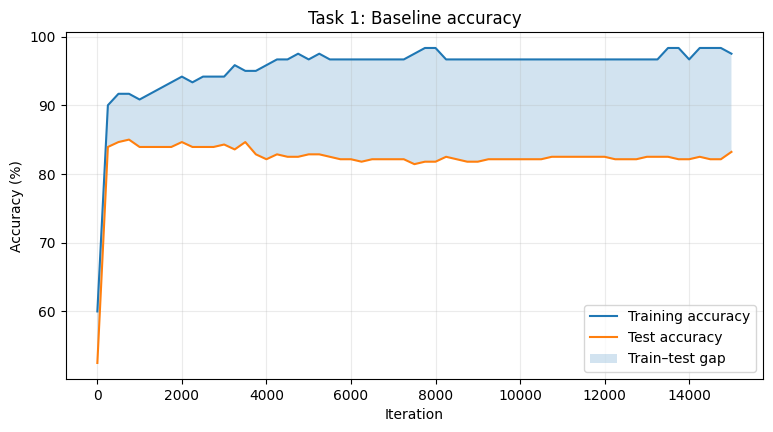

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
it = np.array(baseline_hist["iteration"])
tr = np.array(baseline_hist["train_acc"])
te = np.array(baseline_hist["test_acc"])
ax.plot(it, tr, label="Training accuracy")
ax.plot(it, te, label="Test accuracy")
ax.fill_between(it, tr, te, alpha=.2, label="Train–test gap")
ax.set_xlabel("Iteration"); ax.set_ylabel("Accuracy (%)")
ax.set_title("Task 1: Baseline accuracy")
ax.legend(); ax.grid(alpha=.25); plt.show()

### **3. Decision boundary and interpretation**

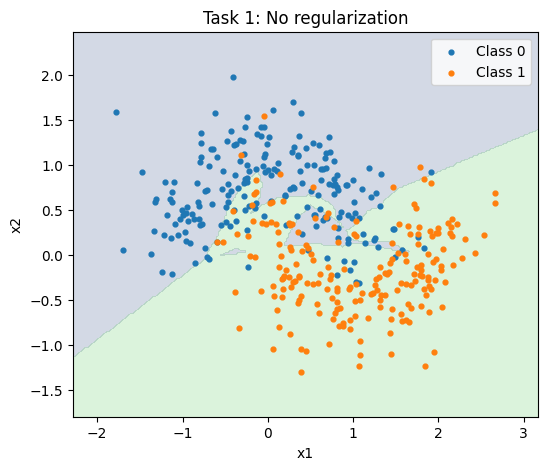

In [6]:
fig, ax = plt.subplots(figsize=(6,5))
plot_decision_boundary(ax, baseline_params, "Task 1: No regularization")
ax.legend(); plt.show()

## **Task 2: Initialization Study**

### **1. Compare zeros, large, and He initialization for 6,000 iterations**

 zeros | final cost=0.688139 | train acc=55.00% | test acc=47.86%
 large | final cost=0.651791 | train acc=55.00% | test acc=47.86%
    he | final cost=0.042372 | train acc=97.50% | test acc=82.14%


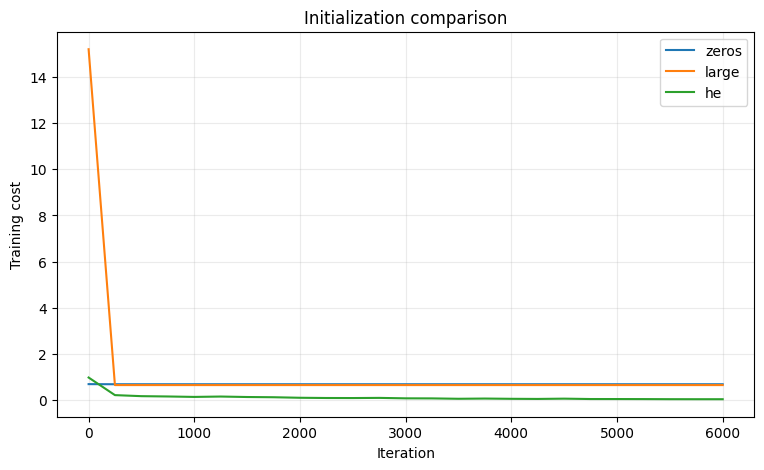

In [7]:
init_results = {}
for mode in ["zeros", "large", "he"]:
    p, h = train_model(X_train, Y_train, X_test, Y_test,
                       iterations=6000, learning_rate=0.3, init_mode=mode,
                       lambd=0.0, keep_prob=1.0, seed=21, log_every=250)
    init_results[mode] = (p, h)
    print(f"{mode:>6} | final cost={compute_cost(forward_propagation(X_train,p)[0],Y_train,p):.6f} "
          f"| train acc={accuracy(X_train,Y_train,p):.2f}% | test acc={accuracy(X_test,Y_test,p):.2f}%")

plt.figure(figsize=(9,5))
for mode, (_, h) in init_results.items():
    plt.plot(h["iteration"], h["cost"], label=mode)
plt.xlabel("Iteration"); plt.ylabel("Training cost"); plt.title("Initialization comparison")
plt.legend(); plt.grid(alpha=.25); plt.show()

### **2. Plot all three decision boundaries**

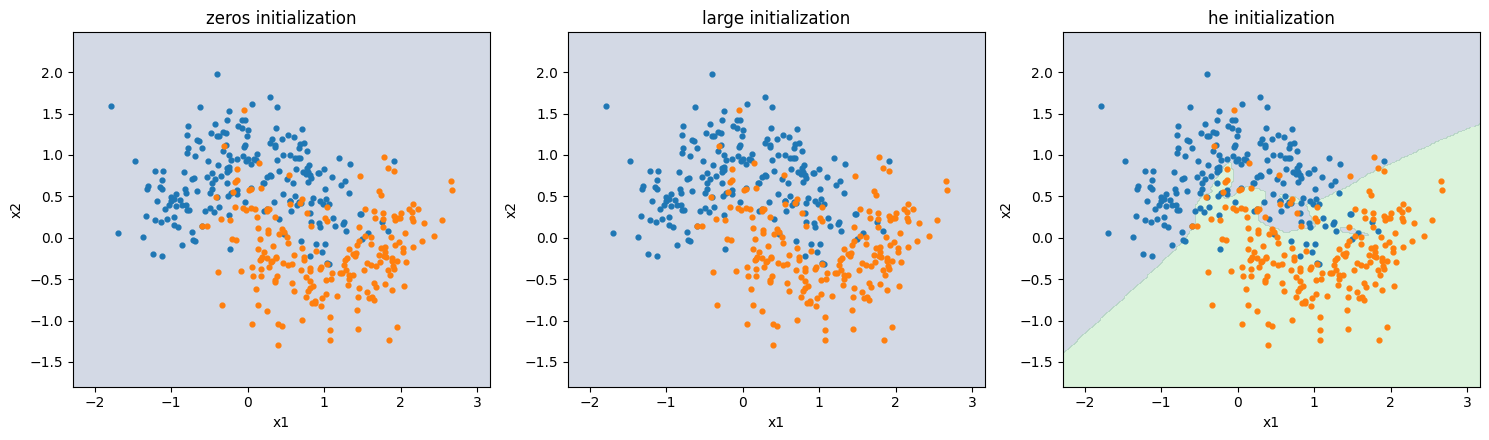

In [8]:
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
for ax, mode in zip(axes, ["zeros","large","he"]):
    p, _ = init_results[mode]
    plot_decision_boundary(ax, p, f"{mode} initialization")
plt.tight_layout(); plt.show()

### **3. Histogram of first-layer Z at initialization for all four modes**

 zeros: std(Z1) = 0.00000000
 small: std(Z1) = 0.01166600
    he: std(Z1) = 1.16659985
 large: std(Z1) = 11.66599852


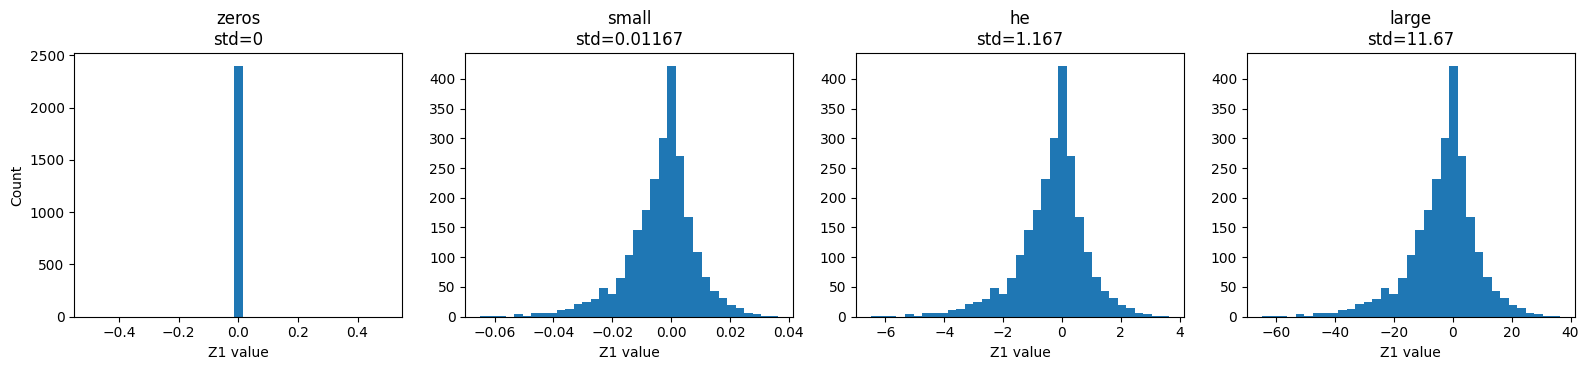

In [9]:
layer_dims = (2,20,20,20,1)
fig, axes = plt.subplots(1,4,figsize=(16,3.8))
for ax, mode in zip(axes, ["zeros","small","he","large"]):
    p = initialize_parameters(layer_dims, mode=mode, seed=7)
    z1 = p["W1"] @ X_train + p["b1"]
    ax.hist(z1.ravel(), bins=35)
    ax.set_title(f"{mode}\nstd={np.std(z1):.4g}")
    ax.set_xlabel("Z1 value")
    print(f"{mode:>6}: std(Z1) = {np.std(z1):.8f}")
axes[0].set_ylabel("Count")
plt.tight_layout(); plt.show()

## **Task 3: L2 Regularization**

### **1. Train the lambda sweep and report accuracy and combined weight norm**

In [10]:
lambda_values = [0, 0.03, 0.1, 0.3, 1, 3]
l2_results = {}
for lam in lambda_values:
    p, h = train_model(X_train, Y_train, X_test, Y_test,
                       iterations=6000, learning_rate=0.3, init_mode="he",
                       lambd=lam, keep_prob=1.0, seed=31, log_every=None)
    l2_results[lam] = p
    print(f"lambda={lam:>4} | train={accuracy(X_train,Y_train,p):6.2f}% "
          f"| test={accuracy(X_test,Y_test,p):6.2f}% | weight norm={weight_norm(p):.4f}")
best_lambda = max(lambda_values, key=lambda lam: accuracy(X_test,Y_test,l2_results[lam]))
print("Best lambda by test accuracy:", best_lambda)

lambda=   0 | train= 96.67% | test= 84.29% | weight norm=17.7914
lambda=0.03 | train= 96.67% | test= 83.93% | weight norm=14.8567
lambda= 0.1 | train= 96.67% | test= 83.93% | weight norm=10.4799
lambda= 0.3 | train= 91.67% | test= 84.64% | weight norm=6.9658
lambda=   1 | train= 90.00% | test= 85.71% | weight norm=4.4791
lambda=   3 | train= 88.33% | test= 83.57% | weight norm=3.0070
Best lambda by test accuracy: 1


### **2. Plot accuracy and weight norm against lambda; mark chosen lambda**

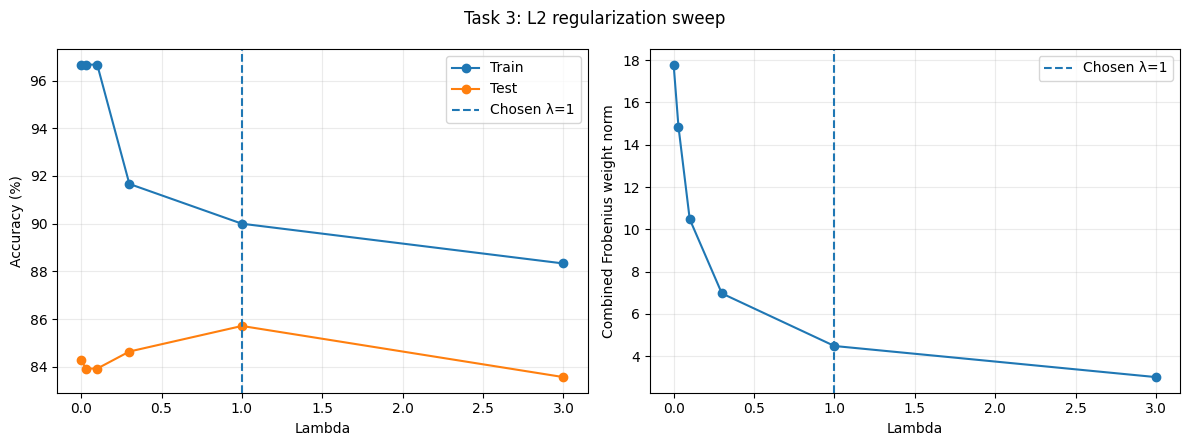

In [11]:
tr_accs = [accuracy(X_train,Y_train,l2_results[l]) for l in lambda_values]
te_accs = [accuracy(X_test,Y_test,l2_results[l]) for l in lambda_values]
norms = [weight_norm(l2_results[l]) for l in lambda_values]

fig, axes = plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot(lambda_values,tr_accs,"o-",label="Train")
axes[0].plot(lambda_values,te_accs,"o-",label="Test")
axes[0].axvline(best_lambda, linestyle="--", label=f"Chosen λ={best_lambda}")
axes[0].set_xlabel("Lambda"); axes[0].set_ylabel("Accuracy (%)"); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot(lambda_values,norms,"o-")
axes[1].axvline(best_lambda, linestyle="--", label=f"Chosen λ={best_lambda}")
axes[1].set_xlabel("Lambda"); axes[1].set_ylabel("Combined Frobenius weight norm"); axes[1].legend(); axes[1].grid(alpha=.25)
fig.suptitle("Task 3: L2 regularization sweep"); plt.tight_layout(); plt.show()

## **Task 4: Inverted Dropout**

### **1. Verify prediction disables dropout; demonstrate incorrect stochastic prediction**

In [12]:
# Train a representative dropout model for the demonstration.
drop_demo_params, _ = train_model(X_train,Y_train,X_test,Y_test,
                                  iterations=4000, learning_rate=0.3,
                                  init_mode="he", lambd=0.0, keep_prob=0.7,
                                  seed=41, log_every=None)
print("Correct deterministic test accuracy:", accuracy(X_test,Y_test,drop_demo_params), "%")

# Deliberately incorrect demonstration: leave dropout active at inference.
for run in (1,2):
    probs, _ = forward_propagation(X_test, drop_demo_params, keep_prob=0.7,
                                   training=True, seed=100+run)
    pred = (probs >= .5).astype(float)
    print(f"Incorrect stochastic prediction run {run}: accuracy={np.mean(pred==Y_test)*100:.2f}%")

Correct deterministic test accuracy: 81.78571428571428 %
Incorrect stochastic prediction run 1: accuracy=81.79%
Incorrect stochastic prediction run 2: accuracy=84.64%


### **2. Sweep keep_prob and tabulate train/test accuracy**

In [13]:
keep_values = [1.0, 0.9, 0.8, 0.7, 0.5, 0.3]
drop_results = {}
for kp in keep_values:
    p, _ = train_model(X_train,Y_train,X_test,Y_test,
                       iterations=6000, learning_rate=0.3, init_mode="he",
                       lambd=0.0, keep_prob=kp, seed=51, log_every=None)
    drop_results[kp] = p
    print(f"keep_prob={kp:.1f} | train={accuracy(X_train,Y_train,p):.2f}% "
          f"| test={accuracy(X_test,Y_test,p):.2f}%")
best_keep = max(keep_values, key=lambda kp: accuracy(X_test,Y_test,drop_results[kp]))
print("Best keep_prob by test accuracy:", best_keep)

keep_prob=1.0 | train=98.33% | test=80.71%
keep_prob=0.9 | train=97.50% | test=83.21%
keep_prob=0.8 | train=93.33% | test=83.21%
keep_prob=0.7 | train=94.17% | test=85.36%
keep_prob=0.5 | train=90.00% | test=80.71%
keep_prob=0.3 | train=85.83% | test=80.71%
Best keep_prob by test accuracy: 0.7


### **3. Plot accuracy against keep_prob and explain the selected value**

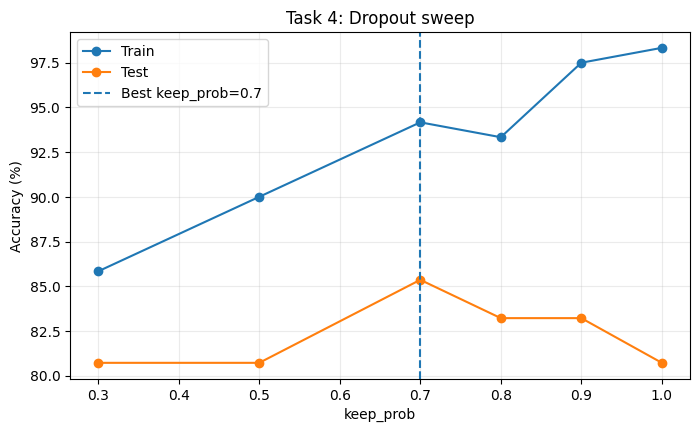

In [14]:
plt.figure(figsize=(8,4.5))
plt.plot(keep_values,[accuracy(X_train,Y_train,drop_results[k]) for k in keep_values],"o-",label="Train")
plt.plot(keep_values,[accuracy(X_test,Y_test,drop_results[k]) for k in keep_values],"o-",label="Test")
plt.axvline(best_keep, linestyle="--", label=f"Best keep_prob={best_keep}")
plt.xlabel("keep_prob"); plt.ylabel("Accuracy (%)"); plt.title("Task 4: Dropout sweep")
plt.legend(); plt.grid(alpha=.25); plt.show()

### **4. Compare decision boundaries: baseline, best L2, best dropout**

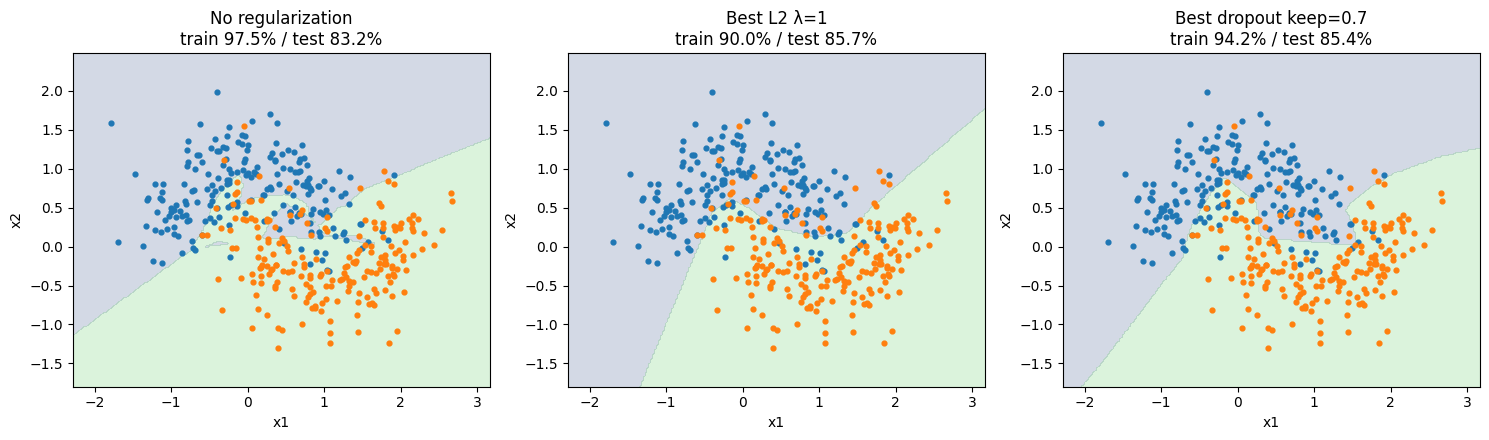

In [15]:
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
models = [
    ("No regularization", baseline_params),
    (f"Best L2 λ={best_lambda}", l2_results[best_lambda]),
    (f"Best dropout keep={best_keep}", drop_results[best_keep])
]
for ax, (name,p) in zip(axes,models):
    title = f"{name}\ntrain {accuracy(X_train,Y_train,p):.1f}% / test {accuracy(X_test,Y_test,p):.1f}%"
    plot_decision_boundary(ax,p,title)
plt.tight_layout(); plt.show()

## **Task 5: Gradient Checking with Regularization**

In [16]:
# Gradient-Check Utilities
def dictionary_to_vector(params):
    keys, vectors = [], []
    for key in sorted(params.keys()):
        keys.append((key, params[key].shape))
        vectors.append(params[key].reshape(-1,1))
    return np.concatenate(vectors, axis=0), keys

def vector_to_dictionary(theta, keys):
    params = {}
    start = 0
    for key, shape in keys:
        size = int(np.prod(shape))
        params[key] = theta[start:start+size].reshape(shape).copy()
        start += size
    return params

def gradients_to_vector(grads, params):
    vectors = []
    for key in sorted(params.keys()):
        vectors.append(grads["d"+key].reshape(-1,1))
    return np.concatenate(vectors, axis=0)

def gradient_check(Xc, Yc, params, lambd=0.0, epsilon=1e-7):
    theta, keys = dictionary_to_vector(params)
    AL, cache = forward_propagation(Xc, params, training=False)
    grads = backward_propagation(AL, Yc, params, cache, lambd=lambd, keep_prob=1.0)
    grad = gradients_to_vector(grads, params)
    gradapprox = np.zeros_like(theta)
    for i in range(theta.shape[0]):
        plus = theta.copy(); plus[i,0] += epsilon
        minus = theta.copy(); minus[i,0] -= epsilon
        pplus = vector_to_dictionary(plus, keys)
        pminus = vector_to_dictionary(minus, keys)
        cplus = compute_cost(forward_propagation(Xc,pplus,training=False)[0],Yc,pplus,lambd)
        cminus = compute_cost(forward_propagation(Xc,pminus,training=False)[0],Yc,pminus,lambd)
        gradapprox[i,0] = (cplus-cminus)/(2*epsilon)
    numerator = np.linalg.norm(grad-gradapprox)
    denominator = np.linalg.norm(grad)+np.linalg.norm(gradapprox)+1e-12
    return float(numerator/denominator), grad, gradapprox, keys

X_gc, Y_gc = X_train[:, :8], Y_train[:, :8]
small_dims = (2,5,4,1)

### **1. Gradient check at raw initialization with lambda = 0**

In [17]:
raw_params = initialize_parameters(small_dims, mode="he", seed=123)
diff_raw, grad_raw, approx_raw, keys_raw = gradient_check(X_gc,Y_gc,raw_params,lambd=0.0)
z2_raw = raw_params["W2"] @ np.maximum(0, raw_params["W1"] @ X_gc + raw_params["b1"]) + raw_params["b2"]
print("Relative difference at raw initialization:", diff_raw)
print("Exact zero entries in Z2 on the gradient-check batch:", int(np.sum(z2_raw == 0)))
print("Z2 shape:", z2_raw.shape)

Relative difference at raw initialization: 1.0537794527221208e-09
Exact zero entries in Z2 on the gradient-check batch: 0
Z2 shape: (4, 8)


### **2. Train 200 iterations and repeat the check**

In [19]:
gc_params = initialize_parameters(small_dims, mode="he", seed=123)
for i in range(200):
    al, cache = forward_propagation(X_gc,gc_params,training=False)
    grads = backward_propagation(al,Y_gc,gc_params,cache,lambd=0.0,keep_prob=1.0)
    gc_params = update_parameters(gc_params,grads,0.1)
diff_after, _, _, _ = gradient_check(X_gc,Y_gc,gc_params,lambd=0.0)
print("Relative difference after 200 iterations:", diff_after)

Relative difference after 200 iterations: 3.2833233717310964e-09


### **3. Gradient check with lambda = 0.7 in both cost and gradient**

In [20]:
diff_l2, _, _, _ = gradient_check(X_gc,Y_gc,gc_params,lambd=0.7)
print("Relative difference with correct L2 cost and gradient:", diff_l2)

Relative difference with correct L2 cost and gradient: 5.634529591693918e-09


### **4. Deliberately omit L2 from gradient and report the difference**

In [21]:
def gradient_check_missing_l2(Xc,Yc,params,lambd=0.7,epsilon=1e-7):
    theta, keys = dictionary_to_vector(params)
    AL, cache = forward_propagation(Xc,params,training=False)
    # Deliberate error: analytical gradient omits L2 term.
    grads = backward_propagation(AL,Yc,params,cache,lambd=0.0,keep_prob=1.0)
    grad = gradients_to_vector(grads,params)
    gradapprox = np.zeros_like(theta)
    for i in range(theta.shape[0]):
        plus=theta.copy(); plus[i,0]+=epsilon
        minus=theta.copy(); minus[i,0]-=epsilon
        pp=vector_to_dictionary(plus,keys); pm=vector_to_dictionary(minus,keys)
        cp=compute_cost(forward_propagation(Xc,pp,training=False)[0],Yc,pp,lambd)
        cm=compute_cost(forward_propagation(Xc,pm,training=False)[0],Yc,pm,lambd)
        gradapprox[i,0]=(cp-cm)/(2*epsilon)
    return float(np.linalg.norm(grad-gradapprox)/(np.linalg.norm(grad)+np.linalg.norm(gradapprox)+1e-12))

diff_missing = gradient_check_missing_l2(X_gc,Y_gc,gc_params,lambd=0.7)
print("Relative difference when L2 is omitted from gradient:", diff_missing)
print("Correct L2 gradient check remains available via gradient_check(..., lambd=0.7).")

Relative difference when L2 is omitted from gradient: 0.8059369831286533
Correct L2 gradient check remains available via gradient_check(..., lambd=0.7).


### **5. Evaluate fixed parameters eight times with dropout active**

In [22]:
fixed_params = gc_params
drop_costs = []
for s in range(8):
    al, _ = forward_propagation(X_gc,fixed_params,keep_prob=0.7,training=True,seed=900+s)
    drop_costs.append(compute_cost(al,Y_gc,fixed_params,lambd=0.0))
print("Eight costs with different dropout masks:", np.array(drop_costs))
print("Standard deviation:", float(np.std(drop_costs)))

Eight costs with different dropout masks: [1.36153 0.67253 2.0313  0.63398 2.18291 1.46926 1.4261  0.9294 ]
Standard deviation: 0.5391573536902131


## **Task 6: Bias–Variance Diagnosis**

### **1. Train four configurations and produce metric table**

In [23]:
configs = {
    "A: small network, no L2": {"dims":(2,2,1), "lambd":0.0},
    "B: deep network, no L2": {"dims":(2,20,20,20,1), "lambd":0.0},
    "C: deep network, lambda=10": {"dims":(2,20,20,20,1), "lambd":10.0},
    "D: deep network, best Task 3 lambda": {"dims":(2,20,20,20,1), "lambd":best_lambda},
}
config_models = {}
for name, cfg in configs.items():
    p, _ = train_model(X_train,Y_train,X_test,Y_test,layer_dims=cfg["dims"],
                       iterations=6000,learning_rate=0.3,init_mode="he",
                       lambd=cfg["lambd"],keep_prob=1.0,seed=71,log_every=None)
    config_models[name] = p
    tracc, teacc = accuracy(X_train,Y_train,p), accuracy(X_test,Y_test,p)
    print(f"{name}\n  train error={100-tracc:.2f}% | train-test gap={tracc-teacc:.2f} pp | test accuracy={teacc:.2f}%")

A: small network, no L2
  train error=11.67% | train-test gap=5.48 pp | test accuracy=82.86%
B: deep network, no L2
  train error=2.50% | train-test gap=15.00 pp | test accuracy=82.50%
C: deep network, lambda=10
  train error=11.67% | train-test gap=5.48 pp | test accuracy=82.86%
D: deep network, best Task 3 lambda
  train error=8.33% | train-test gap=7.38 pp | test accuracy=84.29%


### **2. Plot four decision boundaries side by side**

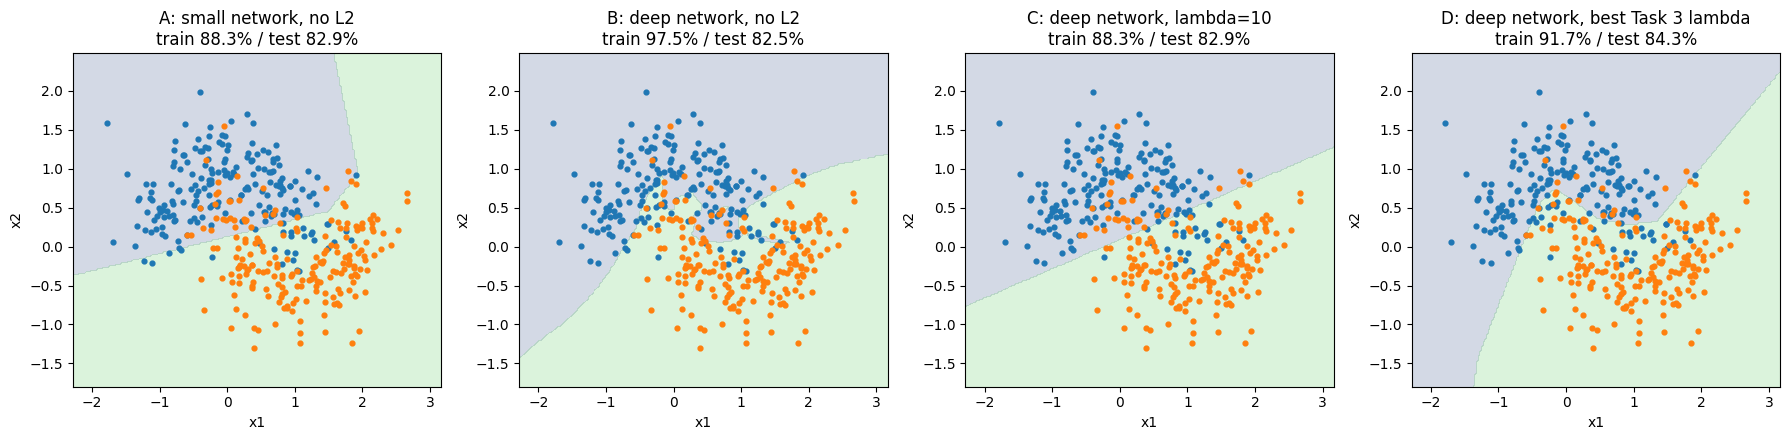

In [24]:
fig, axes = plt.subplots(1,4,figsize=(18,4.5))
for ax,(name,p) in zip(axes,config_models.items()):
    title=f"{name}\ntrain {accuracy(X_train,Y_train,p):.1f}% / test {accuracy(X_test,Y_test,p):.1f}%"
    plot_decision_boundary(ax,p,title)
plt.tight_layout(); plt.show()